# Lecture 1 — Missing data and exact Gaussian queries

## Before you begin

### *Explanation to read*

#### What you will do

Welcome to the first teaching notebook in this course. Here you turn the lecture's equations into calculations, inspect their outputs, and explain what those outputs establish.

Four coordinates of a measurement vector are recorded; three are withheld. You will compute a distribution for the hidden block, choose an estimate under squared loss, and use the same model to predict and generate measurements of a new case. The model parameters are supplied throughout.

We assume a basic knowledge of probability, matrix algebra and Python. New numerical operations are explained where you need them. You are expected to work through each question so you can understand the calculations.

#### Save a copy and start the runtime

In **student notebooks**, placeholders indicate where answers are expected. Save your own copy before editing; in Colab, use **File → Save a copy in Drive**. The **solved notebook** has filled-in answers to help you if you get stuck.

In Colab, connect to a standard CPU runtime. You can also clone the repository locally; in VS Code, select the course repository's `.venv` kernel. Run the supplied setup cells below before starting Question 1.1. The plotting-support cell may take a moment on its first run; it installs only the small course plotting package when needed.

A notebook mixes text cells and code cells. Select a code cell and press **Shift+Enter** to run it; its output appears below. To write a prose or mathematical answer, double-click its text cell, replace the placeholder, and press **Shift+Enter** to display it. Use `$ ... $` for inline mathematics and `$$ ... $$` for a displayed equation.

#### Read, run, then answer

Each section uses three kinds of material:

- **Explanation to read** develops a mathematical or technical idea that you need to understand and use.
- **Code to run** supplies setup, displays or checks, with brief notes about their purpose and output. Read those notes and run the supplied cells. You are not asked to write this code.
- **Questions to answer** asks you to do something. Each numbered question says whether to write code, mathematics or prose. Replace its one unnumbered answer cell: `# answer here` marks a code answer and “answer here” marks a written answer. In the solved reference, that same cell contains a complete answer.

Work **from top to bottom**: read the explanation, run any supporting code, then answer the questions. Later cells use variables created earlier. The runtime remembers values until you restart it. If you change an earlier calculation, rerun the cells that depend on it. Saved output alone does not show that the current code produced it.

After running code, check the requested shapes, values or plot. In written answers, explain the relevant mathematical distinction in your own words; a printed array does not answer an interpretation question.

The sections move from the known model to conditioning, squared-loss estimation, an equivalent linear Gaussian system, forward prediction and generation. Pause and ask for help if a step stops making sense.

#### Using AI assistance

You may use an AI assistant to help with these questions. First identify the mathematical object you need and what is already given. When asking for help, include the question, its nearby formula, and the relevant array names/shapes; an isolated error message often omits the needed context.

I recommend against using any built-in AI or uploading the entire notebook to AI. The notebook works best if the agent has seen as much of the notebook as you have when addressing a specific question, so it is best if you work in copy / paste mode: copying material into an AI chat and then reading and typing what is appropriate or pasting back in the answer.

Ask for an explanation or a small piece of code you can check. Adapt the answer to this notebook's names, run it, and connect it to the displayed equation. If a line is unclear, ask what it computes and why its dimensions work. You should be able to explain your final answer and its assumptions, including code suggested by AI. If code fails, read the final line of the error and identify the cell that caused it before changing the model or its data.

#### What a finished notebook should contain

Keep your code, written explanations and the resulting outputs together. By the end, you should be able to explain the hidden-block distribution and its uncertainty, the estimate selected by squared loss, and how forward prediction and generation answer different questions.

Before you finish:

1. Check that every numbered question has an answer and every requested display is present.
2. Read your outputs and explanations together: shapes and uncertainty statements should agree with the equations.
3. Restart the runtime/kernel and run all cells from the beginning **after filling the answers**. Resolve errors and confirm the supplied checks pass. Running all cells in an untouched student notebook will stop when a later cell needs an answer you have not written yet.
4. Save the completed notebook with its outputs. Follow any submission instructions supplied separately by the instructor.

The supplied checks catch selected numerical mistakes. Passing them is useful feedback; your explanations are still needed to show what the calculations mean.

## Supplied plotting tools

### *Code to run*

#### Load the plotting tools

Imports the plotting helpers; Colab installs the pinned package if needed. They display your calculations. Locally, restart the `.venv` kernel after `uv sync --locked`.

Optional: inspect the [helper source](https://github.com/opherdonchin/ProbabilisticMachineLearning/blob/7304c542dd1b0bfd6762ea08d2cb384ffd7d2e39/notebook_support/src/course_support/l01.py) or use `help(plot_hidden_uncertainty)` to read its inputs.

In [9]:
import importlib.util

if importlib.util.find_spec("course_support") is None:
    if importlib.util.find_spec("pip") is None:
        raise RuntimeError(
            "Restart this notebook's .venv kernel. If the import still fails, "
            "run `uv sync --locked` in the repository terminal, then restart again."
        )
    %pip install --quiet "pml-course-support @ git+https://github.com/opherdonchin/ProbabilisticMachineLearning.git@7304c542dd1b0bfd6762ea08d2cb384ffd7d2e39#subdirectory=notebook_support"

from course_support.l01 import (
    plot_joint_correlation,
    plot_hidden_uncertainty,
    plot_forward_measurements,
)
print("Course plotting tools are ready.")

Course plotting tools are ready.


## 0. Known model and fixed case

### *Explanation to read*

#### The supplied joint Gaussian

Write $X=(X_1^T,X_2^T)^T$ with $X_1\in\mathbb R^3$ and $X_2\in\mathbb R^4$. We know
$$
X\sim\mathcal N\!\left(\begin{pmatrix}\mu_1\\\mu_2\end{pmatrix},
\begin{pmatrix}\Sigma_{11}&\Sigma_{12}\\\Sigma_{21}&\Sigma_{22}\end{pmatrix}\right),
\qquad \mu_1=(-0.5,0.5,1)^T,\quad\mu_2=(0,0.5,-0.5,1)^T.
$$

The joint covariance is positive definite, so its diagonal blocks and conditional covariance matrices are invertible. We check these properties at the end. For this example, we construct the covariance blocks using $J_d=\mathbf1_d\mathbf1_d^T$, $\sigma_1=1$, $\sigma_2=1.2$, $\rho_1=0.70$, $\rho_2=0.80$, $\kappa=0.90$:
$$
\Sigma_{11}=\sigma_1^2[(1-\rho_1)I_3+\rho_1J_3],\qquad
\Sigma_{22}=\sigma_2^2[(1-\rho_2)I_4+\rho_2J_4],
$$
$$
\Sigma_{12}=\kappa\sigma_1\sigma_2\sqrt{\rho_1\rho_2}\,\mathbf1_3\mathbf1_4^T,
\qquad\Sigma_{21}=\Sigma_{12}^T.
$$

#### Representing the blocks in NumPy

The mean blocks are one-dimensional arrays with shapes `(3,)` and `(4,)`. Their covariance blocks are two-dimensional arrays: for example, `Sigma12` has shape `(3,4)`. Matrix-vector multiplication with `@` maps a `(4,)` vector to a `(3,)` vector in this example. A vector does not need to be stored as a column array; `.T` transposes a matrix but leaves a one-dimensional vector's shape unchanged.

`np.block([[A, B], [C, D]])` assembles compatible matrix blocks in the same two-by-two layout as the displayed covariance. The first block row joins `Sigma11` and `Sigma12`; the second joins `Sigma21` and `Sigma22`. This gives the full `(7,7)` covariance.

### *Code to run*

#### Set the dimensions and model parameters

Defines the supplied joint Gaussian; prints the block sizes and joint mean. `mu` concatenates the hidden-block and recorded-block means, in that order. `np.set_printoptions` changes the displayed precision; calculations retain the stored precision.

In [10]:
import numpy as np
from scipy.stats import norm

np.set_printoptions(precision=6, suppress=True)
n1, n2 = 3, 4
mu1 = np.array([-0.5, 0.5, 1.0])
mu2 = np.array([0.0, 0.5, -0.5, 1.0])
mu = np.concatenate([mu1, mu2])
sigma1, sigma2 = 1.0, 1.2
rho1, rho2, kappa = 0.70, 0.80, 0.90
print("Hidden / recorded block sizes:", n1, "/", n2)
print("Joint mean mu:", mu)

Hidden / recorded block sizes: 3 / 4
Joint mean mu: [-0.5  0.5  1.   0.   0.5 -0.5  1. ]


#### Assemble the covariance blocks

Evaluates the covariance formulas and assembles `Sigma`; its printed shape should be `(7,7)`. `np.eye` and `np.ones` supply the identity and all-ones matrices in those formulas.

In [11]:
Sigma11 = sigma1**2 * ((1-rho1)*np.eye(n1) + rho1*np.ones((n1,n1)))
Sigma22 = sigma2**2 * ((1-rho2)*np.eye(n2) + rho2*np.ones((n2,n2)))
Sigma12 = kappa*sigma1*sigma2*np.sqrt(rho1*rho2)*np.ones((n1,n2))
Sigma21 = Sigma12.T
Sigma = np.block([[Sigma11, Sigma12], [Sigma21, Sigma22]])
print("Joint covariance Sigma shape:", Sigma.shape)

Joint covariance Sigma shape: (7, 7)


#### Load the case and expose only its recorded block

This supplied vector represents one simulated case; keep its values unchanged. Slicing separates the recorded coordinates, `x2_obs`, from the withheld coordinates, `x1_true`. Only `x2_obs` is printed and used for inference; the withheld values are revealed later for evaluation.

In [12]:
# Fixed reference case: original seed 2027 / NumPy 2.0.2 provenance.
x_complete = np.array([
    -0.9809265055186939, -0.275006600480288, 1.8920470230380393,
    -0.18413093623310994, -0.06973754657319287,
    -0.07777903828206933, 0.9191872262734604,
])
x1_true = x_complete[:n1].copy()  # Retained only for later evaluation.
x2_obs = x_complete[n1:].copy()  # This is the inference input.
print("Observed block x2_obs:", x2_obs)

Observed block x2_obs: [-0.184131 -0.069738 -0.077779  0.919187]


## 1. Read the known joint and identify the task

### *Code to run*

#### Display the known correlations

Displays the known correlation matrix, with the hidden/recorded boundary after coordinate three. Locate the two within-block regions and the cross-block region. These correlations come from the supplied model parameters.

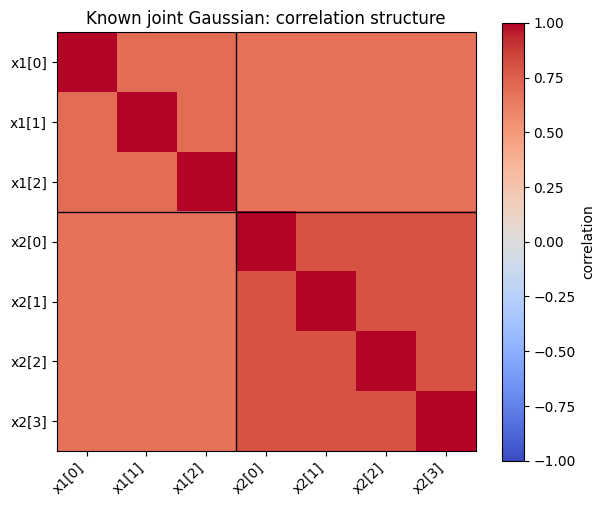

In [13]:
_ = plot_joint_correlation(Sigma, n1)

### *Questions to answer*

#### 1.1 Identify the covariance blocks — mathematics

For $X_1\in\mathbb R^3$ and $X_2\in\mathbb R^4$, state the shape of each of $\Sigma_{11},\Sigma_{12},\Sigma_{21},\Sigma_{22}$ and the full $\Sigma$. Explain which pairs of coordinates an entry of $\Sigma_{12}$ describes.

##### *start answer*

The shapes are $3\times3$, $3\times4$, $4\times3$, $4\times4$, and $7\times7$, respectively. Entry $(i,j)$ of $\Sigma_{12}$ is $\operatorname{Cov}(X_{1i},X_{2j})$: a covariance between a hidden-block and an observed-block coordinate.

##### *end answer*

#### 1.2 Calculate a covariance and its correlation — mathematics

The supplied construction makes every cross-block covariance equal to $\kappa\sigma_1\sigma_2\sqrt{\rho_1\rho_2}$. Using the given parameter values, calculate $\operatorname{Cov}(X_{11},X_{21})$ and divide by the marginal standard deviations $\sigma_1\sigma_2$ to obtain $\operatorname{Corr}(X_{11},X_{21})$. Also state the correlations between distinct coordinates within each block.

##### *start answer*

$$
\operatorname{Cov}(X_{11},X_{21})=0.90(1)(1.2)\sqrt{0.70\cdot0.80}\approx0.808198,
$$
$$
\operatorname{Corr}(X_{11},X_{21})=0.90\sqrt{0.70\cdot0.80}\approx0.673498.
$$
Distinct coordinates have correlation $0.70$ within $X_1$ and $0.80$ within $X_2$. The nonzero cross-block dependence makes the recorded block informative about the hidden block in this Gaussian model.

##### *end answer*

### *Explanation to read*

#### The reconstruction task

We want to infer the hidden part of a case from its recorded measurements. Write this query as $p(z_*\mid x_*)$, where $z_*$ is the unobserved quantity and $x_*$ is the available information. Here the joint model is supplied rather than estimated from a training dataset; its parameters $\mu,\Sigma$ are fixed. Reconstruction should first report a conditional distribution; choosing a point estimate requires a loss function.

### *Questions to answer*

#### 1.3 Specify this reconstruction problem — prose and mathematics

We withhold the three values in `x1_true`, observe the four values in `x2_obs`, and know $\mu,\Sigma$. Identify the unobserved quantity $z_*$ and available information $x_*$ in the conditional query $p(z_*\mid x_*)$. Write the concrete target distribution and distinguish the unknown values from model parameters.

##### *start answer*

Here $z_*=X_1$ and $x_*=x_{2,\mathrm{obs}}$. The target is
$$
p(x_1\mid x_{2,\mathrm{obs}},\mu,\Sigma).
$$
This conditional describes the hidden coordinates of this case. The unknown is a three-dimensional value, not $\mu$ or $\Sigma$. Those parameters are supplied, so this notebook performs inference with a known model and no parameter fitting. `x1_true` is a separately retained evaluation reference, not evidence supplied to this conditional.

##### *end answer*

### *Explanation to read*

#### Section summary

We identified the covariance blocks for hidden and recorded coordinates, the dependence between those blocks, and the conditional distribution needed to infer the hidden coordinates from the recorded ones.

## 2. Evaluate the exact conditional distribution

### *Explanation to read*

#### Compute the hidden-block conditional distribution

Apply the lecture's block-Gaussian equations:
$$
X_1\mid X_2=x_{2,\mathrm{obs}}\sim\mathcal N(m,V),
$$
$$
m=\mu_1+\Sigma_{12}\Sigma_{22}^{-1}(x_{2,\mathrm{obs}}-\mu_2),\qquad
V=\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.
$$

The covariance $V$ is the **Schur complement** of $\Sigma_{22}$ in $\Sigma$. Here it describes uncertainty about the hidden coordinates after conditioning on the recorded coordinates.

The **innovation** $x_{2,\mathrm{obs}}-\mu_2$ is the difference between the recorded values and their model mean. `np.linalg.solve(A, B)` solves $AU=B$ for $U$; when $A$ is invertible, this evaluates $A^{-1}B$ without explicitly forming an inverse. A vector right-hand side produces a vector; a matrix right-hand side solves for all its columns. Keep the displayed multiplication order.

### *Questions to answer*

#### 2.1 Compute the conditional mean — code

Using `np.linalg.solve(A, B)` for $A^{-1}B$, calculate `innovation = x2_obs - mu2` and
$$
m=\mu_1+\Sigma_{12}\Sigma_{22}^{-1}(x_{2,\mathrm{obs}}-\mu_2).
$$
Store the result as `conditional_mean`; print it and its shape. Check in a code comment how a $(3,4)$ matrix acts on the solved $(4,)$ vector.

In [14]:
##### *start answer*

innovation = x2_obs - mu2
# Sigma12 (3,4) @ solved innovation (4,) produces a (3,) vector.
conditional_mean = mu1 + Sigma12 @ np.linalg.solve(Sigma22, innovation)
print("Conditional mean:", conditional_mean)
print("Shape:", conditional_mean.shape)

##### *end answer*

Conditional mean: [-0.568086  0.431914  0.931914]
Shape: (3,)


#### 2.2 Compute the conditional covariance — code

Use a matrix right-hand side in `np.linalg.solve(Sigma22, Sigma21)` to evaluate
$$
V=\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.
$$
Store it as `conditional_cov`, print it and its shape, and give the shapes of the solve result and final product in a code comment.

In [15]:
##### *start answer*

# solve result: (4,3); Sigma12 (3,4) @ result (4,3) gives (3,3).
conditional_cov = Sigma11 - Sigma12 @ np.linalg.solve(Sigma22, Sigma21)
print("Conditional covariance:\n", conditional_cov)
print("Shape:", conditional_cov.shape)

##### *end answer*

Conditional covariance:
 [[0.466353 0.166353 0.166353]
 [0.166353 0.466353 0.166353]
 [0.166353 0.166353 0.466353]]
Shape: (3, 3)


### *Explanation to read*

#### Individual marginal intervals

For covariance $V$, `np.diag(V)` extracts its diagonal variances; `np.sqrt(...)` gives the marginal standard deviations. A Gaussian coordinate with mean $m_j$ and SD $s_j$ has central 90% interval
$$
[m_j-q s_j,\ m_j+q s_j],\qquad q=\Phi^{-1}(0.95)\approx1.64485.
$$
The supplied `z90 = norm.ppf(0.95)` is this normal quantile. These are **individual marginal intervals**: each coordinate has conditional probability 0.90 in its own interval. The full covariance still contains cross-coordinate dependence.

### *Code to run*

#### Set the normal interval multiplier

Stores and prints the standard-normal 95th percentile as `z90`, the multiplier $q$ above. Expect approximately 1.644854.

In [16]:
z90 = norm.ppf(0.95)
print(f"Central 90% interval multiplier: {z90:.6f}")

Central 90% interval multiplier: 1.644854


### *Questions to answer*

#### 2.3 Summarize the marginal uncertainties — code

The exact conditional distribution is $\mathcal N(m,V)$, with $m$ stored in `conditional_mean` and $V$ stored in `conditional_cov`. Compute `conditional_sd` from the diagonal of `conditional_cov`, then the lower and upper central 90% endpoints using the supplied `z90`. Store the endpoints as `conditional_90_low` and `conditional_90_high` and print all three arrays.

In [17]:
##### *start answer*

conditional_sd = np.sqrt(np.diag(conditional_cov))
conditional_90_low = conditional_mean - z90 * conditional_sd
conditional_90_high = conditional_mean + z90 * conditional_sd
print("Marginal SD:", conditional_sd)
print("Individual 90% lower:", conditional_90_low)
print("Individual 90% upper:", conditional_90_high)

##### *end answer*

Marginal SD: [0.6829 0.6829 0.6829]
Individual 90% lower: [-1.691357 -0.691357 -0.191357]
Individual 90% upper: [0.555185 1.555185 2.055185]


### *Code to run*

#### Compare the conditional intervals with the withheld values

Reveals `x1_true` for evaluation alongside individual 90% intervals: gray for the unconditional marginal, blue for the conditional marginal. The withheld values did not enter your conditional calculation; the helper displays your computed result.

Hidden simulation truth (evaluation only): [-0.980927 -0.275007  1.892047]


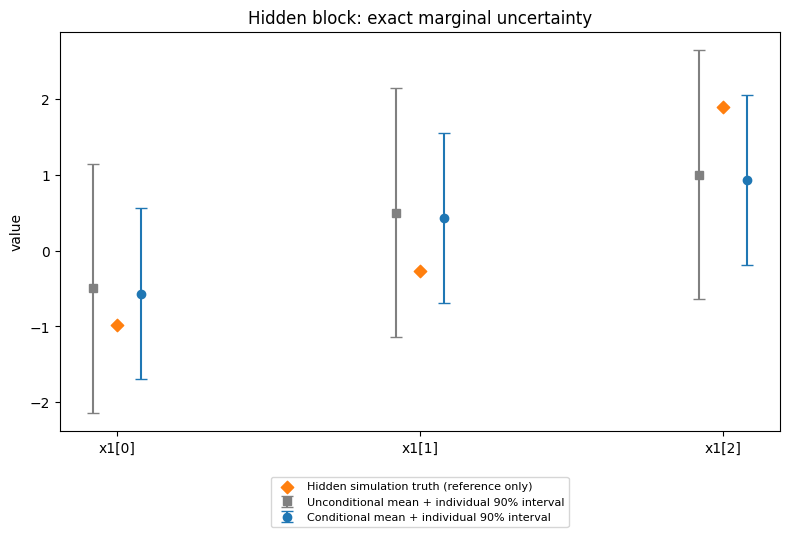

In [18]:
print("Hidden simulation truth (evaluation only):", x1_true)
_ = plot_hidden_uncertainty(
    mu1, Sigma11, conditional_mean, conditional_sd, x1_true,
    interval_quantile=z90,
)

### *Questions to answer*

#### 2.4 What has been computed? — prose

Our exact result is $\mathcal N(m,V)$, with three individual marginal 90% intervals. Explain why reporting only $m$ loses information, and why the probability that **all three** coordinates fall in their displayed intervals cannot simply be labelled 90%. Which computed object retains the conditional dependence?

##### *start answer*

The mean $m$ is a point summary; it omits the uncertainty about the unknown vector. Each interval describes one marginal coordinate, so its 90% statement does not imply a simultaneous 90% statement for the vector. The covariance $V$ retains the variances and cross-coordinate covariances. It is part of the exact conditional law, not an uncertainty in an estimated mean.

##### *end answer*

### *Explanation to read*

#### Section summary

The conditional mean is approximately $(-0.568,0.432,0.932)$ and each marginal SD is approximately $0.683$. We evaluated the full exact Gaussian law and its individual marginal intervals. Remaining uncertainty is present even with exact computation; the withheld values need not equal the conditional mean.

## 3. Select an action under squared loss

### *Explanation to read*

#### A distribution and a loss determine the action

The **action** $a\in\mathbb R^3$ is the vector we report as our estimate of the hidden coordinates. The lecture’s vector squared-loss identity gives
$$
R(a\mid x_{2,\mathrm{obs}})
=E_{\mathrm{model}}[\|X_1-a\|^2\mid x_{2,\mathrm{obs}}]
=\operatorname{tr}(V)+\|m-a\|^2.
$$
Here $m$ and $V$ are the conditional mean/covariance already computed. The loss is the **sum** of squared coordinate errors, without dividing by three. This identity holds for any conditional distribution with finite second moments. The Gaussian model gives the particular $m$ and $V$ used here.

`np.trace(V)` adds a matrix's diagonal entries. `np.sum((u-v)**2)` computes the squared Euclidean distance between same-shaped vectors.

The risk averages over possible hidden vectors under the conditional model. Evaluating $\|x_{1,\mathrm{true}}-a\|^2$ uses one particular withheld vector instead; its realized error can differ from that conditional expectation.

### *Questions to answer*

#### 3.1 Choose the squared-loss action — mathematics

Using $R(a\mid x_{2,\mathrm{obs}})=\operatorname{tr}(V)+\|m-a\|^2$, identify the minimizing action and the minimum conditional model risk. Which term describes the remaining uncertainty given the recorded measurements, and which term penalizes choosing an estimate different from the conditional mean? Apply the supplied identity; no new proof is required.

##### *start answer*

The squared distance is nonnegative and vanishes exactly when $a=m$, so
$$
a^*=m,\qquad R(a^*\mid x_{2,\mathrm{obs}})=\operatorname{tr}(V).
$$
The trace describes remaining conditional uncertainty under the supplied model. The term $\|m-a\|^2$ is the excess conditional risk caused by choosing another action. This selects a point decision from a distribution; it does not replace that distribution.

##### *end answer*

#### 3.2 Compute the chosen action and its model risk — code

Set `action_mean` to the exact `conditional_mean`, then use `np.trace(conditional_cov)` to calculate `risk_mean`, the minimum conditional expected **sum** of squared errors. Print the action and risk. Do not use `x1_true` in this calculation.

In [19]:
##### *start answer*

action_mean = conditional_mean
risk_mean = np.trace(conditional_cov)
print("Squared-loss action:", action_mean)
print("Minimum conditional model risk:", risk_mean)

##### *end answer*

Squared-loss action: [-0.568086  0.431914  0.931914]
Minimum conditional model risk: 1.399058823529412


### *Code to run*

#### Evaluate this case’s squared error

Computes the realized sum of squared coordinate errors using the withheld reference. Prints it beside your conditional model expected risk so you can compare the two quantities.

In [13]:
realized_error_mean = np.sum((x1_true - action_mean)**2)
print("Conditional model expected risk:", risk_mean)
print("This case's realized squared error:", realized_error_mean)

Conditional model expected risk: 1.399058823529412
This case's realized squared error: 1.5920294059108695


### *Questions to answer*

#### 3.3 Separate expected risk from this draw's error — prose

The supplied cell prints `risk_mean` and `realized_error_mean`. Explain what is averaged in the former, why the two numbers need not be equal, and whether a small error on this one hidden case validates the Gaussian model or establishes average real-world reconstruction performance.

##### *start answer*

`risk_mean` averages squared error over $X_1\mid X_2=x_{2,\mathrm{obs}}$ under the supplied model. `realized_error_mean` uses one particular hidden value from that distribution; individual losses vary, so equality is not expected. Squared-loss optimality is an expected-risk statement, not guaranteed exact reconstruction of every case. One simulated case does not validate the model or establish average real-world performance.

##### *end answer*

### *Explanation to read*

#### Section summary

Squared loss selects the conditional mean and minimum conditional model risk `trace(conditional_cov)`, approximately 1.399059. This expected error under the model differs from the error on one simulated case. We have not measured average reconstruction performance on real data.

## 4. Express the same joint as a linear Gaussian system

### *Explanation to read*

#### State, measurement and independent noise

We can write the same joint Gaussian as a **linear Gaussian system (LGS)**:
$$
Z\sim\mathcal N(\mu_z,\Sigma_z),\qquad Y=WZ+b+\varepsilon,
\qquad \varepsilon\sim\mathcal N(0,\Omega),\quad \varepsilon\perp Z.
$$
The state is the hidden block and the measurement is the recorded block. We describe the state by $p(z)$ and the measurement given that state by $p(y\mid z)$; their product gives the same joint distribution. No parameters are fitted. Writing the joint this way does not establish a physical sensor mechanism or a causal relationship.

### *Questions to answer*

#### 4.1 Identify the state and measurement — code with comments

The hidden block was $X_1$ and the recorded block was $X_2$. Assign `mu_z`, `Sigma_z` and `y` from the existing arrays. Use comments to state the mapping of $Z,Y$ and the shapes of their means/covariances.

In [14]:
##### *start answer*

# Z = X1 in R^3; mu_z has shape (3,) and Sigma_z has shape (3,3).
mu_z = mu1
Sigma_z = Sigma11
# Y = X2 in R^4; y is this case's observed measurement, shape (4,).
y = x2_obs

##### *end answer*

### *Explanation to read*

#### Find the measurement distribution given the state

In the original block notation, the measurement mean and covariance given the hidden state are
$$
E[X_2\mid X_1]=\mu_2+\Sigma_{21}\Sigma_{11}^{-1}(X_1-\mu_1),
$$
$$
\operatorname{Cov}(X_2\mid X_1)
=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}.
$$
These are the same conditional-Gaussian equations, now describing $X_2$ given $X_1$. Use them to identify $W$, $b$ and $\Omega$ in the LGS.

### *Questions to answer*

#### 4.2 Identify the LGS parameters — mathematics

With $Z=X_1$ and $Y=X_2$, match the supplied conditional mean to $WZ+b$ and the conditional covariance to $\Omega$. Write $W,b,\Omega$ in terms of the original blocks, and give their shapes.

##### *start answer*

$$
W=\Sigma_{21}\Sigma_{11}^{-1}\quad(4\times3),\qquad
b=\mu_2-W\mu_1\quad(4\text{-vector}),
$$
$$
\Omega=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}\quad(4\times4).
$$
$\Omega$ is the residual measurement covariance conditional on the state; it is not the unconditional covariance of $Y$.

##### *end answer*

### *Explanation to read*

#### Compute `W` with a transpose and `solve`

`np.linalg.solve(A, B)` evaluates $A^{-1}B$, with the inverse multiplying $B$ on the left. In $W=\Sigma_{21}\Sigma_{11}^{-1}$ the inverse is on the right. Use the covariance symmetries $\Sigma_{11}^T=\Sigma_{11}$ and $\Sigma_{12}^T=\Sigma_{21}$:
$$
(\Sigma_{11}^{-1}\Sigma_{12})^T=\Sigma_{21}\Sigma_{11}^{-1}.
$$
Thus `np.linalg.solve(Sigma11, Sigma12).T` produces the $(4,3)$ matrix.

### *Questions to answer*

#### 4.3 Implement the observation mean — code

Use the transpose identity above to compute $W=\Sigma_{21}\Sigma_{11}^{-1}$ with `np.linalg.solve`, without forming the inverse. Then compute `b = mu2 - W @ mu1`. Print `W`, `b` and their shapes.

In [15]:
##### *start answer*

W = np.linalg.solve(Sigma11, Sigma12).T
b = mu2 - W @ mu1
print("W:\n", W)
print("b:", b)
print("Shapes:", W.shape, b.shape)

##### *end answer*

W:
 [[0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]]
b: [-0.336749  0.163251 -0.836749  0.663251]
Shapes: (4, 3) (4,)


#### 4.4 Implement the residual covariance — code

Apply
$$
\Omega=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}
$$
using `np.linalg.solve(Sigma11, Sigma12)` for the inverse product. Store the result as `Omega`, print it and its shape, and identify in a code comment why its shape is $(4,4)$.

In [16]:
##### *start answer*

# Measurement noise has four components, so its covariance is (4,4).
Omega = Sigma22 - Sigma21 @ np.linalg.solve(Sigma11, Sigma12)
print("Omega:\n", Omega)
print("Shape:", Omega.shape)

##### *end answer*

Omega:
 [[0.62352 0.33552 0.33552 0.33552]
 [0.33552 0.62352 0.33552 0.33552]
 [0.33552 0.33552 0.62352 0.33552]
 [0.33552 0.33552 0.33552 0.62352]]
Shape: (4, 4)


### *Explanation to read*

#### Section summary

We identified `Z = X1` as the state and `Y = X2` as the measurement, then computed `W`, `b` and `Omega`. Together they specify the distribution of the measurement given the state. The joint Gaussian is unchanged and no parameters were fitted.

## 5. Predict the measurements of a new case

### *Explanation to read*

#### Average over the unknown state

Before observing a new case’s measurement, average over its possible states. This marginalization gives
$$
p(y_{\mathrm{new}})=\int p(y_{\mathrm{new}}\mid z_{\mathrm{new}})p(z_{\mathrm{new}})\,dz_{\mathrm{new}}
=\mathcal N(\mu_y,\Sigma_{yy}),
$$
$$
\mu_y=W\mu_z+b,\qquad \Sigma_{yy}=W\Sigma_zW^T+\Omega.
$$
The term $W\Sigma_zW^T$ is measurement variation due to the random state; $\Omega$ adds independent measurement noise. This **forward marginal** describes a new measurement before observation. The new case is independent of the original case under the known parameters, so the original measurement `y` is not used.

### *Questions to answer*

#### 5.1 Compute the forward marginal — code

Using the LGS arrays, calculate `mu_y = W @ mu_z + b` and `Sigma_yy = W @ Sigma_z @ W.T + Omega`. Print both. Use comments to distinguish the two contributions to `Sigma_yy`. These are the moments of $p(y_{\mathrm{new}})$, not of the hidden-block conditional.

In [ ]:
##### *start answer*

mu_y = W @ mu_z + b
# W @ Sigma_z @ W.T propagates state variation; Omega adds independent noise.
Sigma_yy = W @ Sigma_z @ W.T + Omega
print("Forward measurement mean:", mu_y)
print("Forward measurement covariance:\n", Sigma_yy)

##### *end answer*

### *Explanation to read*

#### The LGS must recover the original Gaussian results

The LGS was constructed from the original joint, so its forward marginal must have mean $\mu_2$ and covariance $\Sigma_{22}$. The supplied checks also recompute the conditional distribution of the hidden coordinates given the **original measurement**, now using LGS notation:
$$
C=\Sigma_zW^T,\qquad m_{\mathrm{LGS}}=\mu_z+C\Sigma_{yy}^{-1}(y-\mu_y),\qquad
V_{\mathrm{LGS}}=\Sigma_z-C\Sigma_{yy}^{-1}C^T.
$$
These identities check that the LGS gives the same conditional mean and covariance as the original block equations.

#### Reading numerical comparisons

Floating-point calculations can give slightly different results for equivalent expressions. `np.allclose(a, b)` returns a Boolean indicating agreement within numerical tolerances. `np.testing.assert_allclose(a, b)` raises an error when the comparison fails, stopping execution so you can revisit the calculation. Its `atol` sets an absolute tolerance; `rtol` scales tolerance with the reference values. Here `rtol=0` uses only the absolute tolerance.

These comparisons check consistency of the two computations within the supplied model. Agreement does not establish that the Gaussian model describes real measurements adequately.

### *Code to run*

#### Check the LGS mean and covariance calculations

Compares the forward moments with the original recorded-block marginal, then evaluates the displayed LGS conditional identities. Expect four `True` results and no assertion error; the conditional comparisons use absolute tolerance $10^{-12}$.

In [ ]:
print("Original marginal mean recovered:", np.allclose(mu_y, mu2))
print("Original marginal covariance recovered:", np.allclose(Sigma_yy, Sigma22))
Sigma_zy = Sigma_z @ W.T
lgs_mean = mu_z + Sigma_zy @ np.linalg.solve(Sigma_yy, y - mu_y)
lgs_cov = Sigma_z - Sigma_zy @ np.linalg.solve(Sigma_yy, Sigma_zy.T)
np.testing.assert_allclose(lgs_mean, conditional_mean, atol=1e-12, rtol=0)
np.testing.assert_allclose(lgs_cov, conditional_cov, atol=1e-12, rtol=0)
print("Same conditional mean recovered:", np.allclose(lgs_mean, conditional_mean))
print("Same conditional covariance recovered:", np.allclose(lgs_cov, conditional_cov))

### *Questions to answer*

#### 5.2 Distinguish the three distributions — prose and mathematics

For this LGS, distinguish (i) $p(z\mid y_{\mathrm{obs}})$, (ii) $p(y\mid z)$ for a specified state, and (iii) $p(y_{\mathrm{new}})$ before a new measurement. Which describes the original hidden coordinates given their recorded measurement? Which has covariance $\Omega$, and which has covariance $W\Sigma_zW^T+\Omega$? Explain why the original `y` is absent from the new-case marginal.

##### *start answer*

(i) $p(z\mid y_{\mathrm{obs}})$ reconstructs the original hidden block, with mean/covariance already stored as `conditional_mean` and `conditional_cov`.

(ii) $p(y\mid z)=\mathcal N(Wz+b,\Omega)$ describes measurement uncertainty for a specified state.

(iii) $p(y_{\mathrm{new}})=\mathcal N(\mu_y,W\Sigma_zW^T+\Omega)$ averages over the new state's uncertainty as well. Under this known fixed model, a new independent case is drawn from the same joint; the original measurement does not update its parameters or condition its state. Therefore the new-case marginal does not use the original `y`.

##### *end answer*

### *Explanation to read*

#### Section summary

The forward marginal reproduces the original recorded-block marginal. We distinguished reconstruction conditional on an original measurement, measurements conditional on a specified state, and new measurements before observation.

## 6. Generate one new state and measurement

### *Explanation to read*

#### Draw a state and independent measurement noise

Generation uses the same known model:
$$
z_{\mathrm{new}}\sim\mathcal N(\mu_z,\Sigma_z),\qquad
\varepsilon_{\mathrm{new}}\sim\mathcal N(0,\Omega)\text{ independently},\qquad
y_{\mathrm{new}}=Wz_{\mathrm{new}}+b+\varepsilon_{\mathrm{new}}.
$$
The new state is drawn from its unconditional law, independently of the original case. Independent noise then supplies the measurement variation conditional on that state.

`rng_new.multivariate_normal(mean, cov)` returns one Gaussian vector when no `size` is specified. Consecutive calls draw the state and noise independently in this simulation. `np.zeros(n2)` supplies the four-component zero noise mean.

### *Code to run*

#### Initialize the new-case generator

Creates `rng_new` and prints its seed, 2028, without drawing a sample. Generated values may vary across numerical-library implementations; their distribution and shapes are what matter.

In [ ]:
FRESH_RANDOM_SEED = 2028
rng_new = np.random.default_rng(FRESH_RANDOM_SEED)
print("Fresh-case generator initialized with seed:", FRESH_RANDOM_SEED)

### *Questions to answer*

#### 6.1 Generate a new case — code

Draw `z_new` from the **unconditional** $\mathcal N(\mu_z,\Sigma_z)$ and `epsilon_new` independently from $\mathcal N(0,\Omega)$ using `rng_new.multivariate_normal`. Form `y_new = W @ z_new + b + epsilon_new`. Print the state, noise, measurement and their shapes, which should be `(3,)`, `(4,)`, `(4,)`. Do not use the original hidden-block conditional or its observed `y` for these draws.

In [ ]:
##### *start answer*

z_new = rng_new.multivariate_normal(mu_z, Sigma_z)
epsilon_new = rng_new.multivariate_normal(np.zeros(n2), Omega)
y_new = W @ z_new + b + epsilon_new
print("Fresh generated state:", z_new)
print("Fresh independent noise:", epsilon_new)
print("Fresh generated measurement:", y_new)
print("Shapes:", z_new.shape, epsilon_new.shape, y_new.shape)

##### *end answer*

### *Code to run*

#### Display new and recorded measurements

Displays individual 90% intervals from your analytic forward marginal, with `y_new` and the original recorded `y` as reference points. Neither point estimates the population moments or changes the intervals.

In [ ]:
_ = plot_forward_measurements(
    mu_y, Sigma_yy, y_new, y, interval_quantile=z90,
)

### *Questions to answer*

#### 6.2 What did generation establish? — prose

We used one new `z_new`, independent `epsilon_new`, and `y_new = W @ z_new + b + epsilon_new`. Explain why this generates a new possible case rather than imputing the original case, and why agreement of a displayed measurement with a marginal interval would not verify the forward mean/covariance or validate the model.

##### *start answer*

The new state is drawn from the unconditional state law and is not conditioned on the original measurement. Its new measurement follows the LGS equation with new independent noise, so the pair is a new possible case. Inferring the original hidden coordinates instead conditions on `x2_obs`. One draw illustrates model generation; it does not estimate or empirically verify a mean/covariance, and an individual interval is not a model-validation test.

##### *end answer*

### *Explanation to read*

#### Section summary

We generated one new state/measurement pair by the LGS vector equation. Generation uses the known law for a new case; the original hidden coordinates are inferred by conditioning on their recorded measurements.

## 7. Check your calculations and consolidate the results

### *Explanation to read*

#### What the covariance checks establish

These checks verify that the computed arrays have the expected shapes and valid covariances. A covariance must be symmetric and positive semidefinite. The joint covariance $\Sigma$ is positive definite, and so are its conditional and residual covariances. These matrices therefore have strictly positive eigenvalues. `np.linalg.eigvalsh` computes the eigenvalues of a symmetric matrix; the checks compare them with zero.

The reduction $\Sigma_{11}-V$ must also be positive semidefinite: conditioning cannot increase the variance of any linear combination of the hidden coordinates in this Gaussian model. That check allows a small negative numerical tolerance for rounding. A failed assertion identifies a calculation to revisit; successful checks do not replace your written interpretations or assess the model's fit to real data.

#### Check the generator’s mean and covariance

The generator starts with independent $Z$ and $\varepsilon$, so their joint covariance is block diagonal. Its output $(Z,Y)$ is an affine transformation:
$$
\begin{pmatrix}Z\\Y\end{pmatrix}
=A\begin{pmatrix}Z\\\varepsilon\end{pmatrix}+\begin{pmatrix}0\\b\end{pmatrix},\qquad
A=\begin{pmatrix}I_3&0\\W&I_4\end{pmatrix}.
$$
For a fixed matrix $A$, $\operatorname{Cov}(AU+c)=A\operatorname{Cov}(U)A^T$. This identity checks the covariance of the distribution generated by these equations. One simulated case cannot verify that covariance by comparison with data.

### *Code to run*

#### Check shapes and covariance properties

Checks array dimensions, covariance symmetry and positive definiteness, and the positive semidefinite covariance reduction. A confirmation appears after these assertions pass.

In [ ]:
assert mu.shape == (7,) and Sigma.shape == (7,7)
assert conditional_mean.shape == (3,) and conditional_cov.shape == (3,3)
assert W.shape == (4,3) and b.shape == (4,) and Omega.shape == (4,4)
for covariance in (Sigma, conditional_cov, Omega):
    np.testing.assert_allclose(covariance, covariance.T, atol=1e-14, rtol=0)
    assert np.all(np.linalg.eigvalsh(covariance) > 0)
assert np.all(np.linalg.eigvalsh(Sigma11 - conditional_cov) > -1e-12)
print("Shape, covariance and variance-reduction checks passed.")

#### Check the fixed-case answers and reconstructed moments

Checks the conditional results against reference values and the LGS moments against the original blocks. The last assertion checks the generated vectors’ shapes. A confirmation appears after these assertions pass.

In [ ]:
np.testing.assert_allclose(conditional_mean, [-0.568,0.432,0.932], atol=5e-4, rtol=0)
np.testing.assert_allclose(conditional_sd, np.full(n1,0.683), atol=5e-4, rtol=0)
np.testing.assert_allclose(risk_mean, 1.399058823529412, atol=1e-12, rtol=0)
np.testing.assert_allclose(Sigma_zy, Sigma12, atol=1e-14, rtol=0)
np.testing.assert_allclose(mu_y, mu2, atol=1e-14, rtol=0)
np.testing.assert_allclose(Sigma_yy, Sigma22, atol=1e-14, rtol=0)
assert z_new.shape == (3,) and epsilon_new.shape == (4,) and y_new.shape == (4,)
print("Fixed-case answers and LGS moment checks passed.")

#### Verify the generated joint mean and covariance

Builds the independent state/noise covariance and affine map above, then checks their implied joint covariance and mean against `Sigma` and `mu`. Confirms that the generator’s moments match the original joint after both checks pass.

In [ ]:
base_cov = np.block([[Sigma_z, np.zeros((n1,n2))],
                     [np.zeros((n2,n1)), Omega]])
affine_map = np.block([[np.eye(n1), np.zeros((n1,n2))],
                       [W, np.eye(n2)]])
np.testing.assert_allclose(affine_map @ base_cov @ affine_map.T, Sigma, atol=1e-12, rtol=0)
np.testing.assert_allclose(np.concatenate([mu_z, mu_y]), mu, atol=1e-12, rtol=0)
print("Generator mean and covariance match the original joint.")

### *Explanation to read*

#### What this notebook established

One known joint Gaussian answered the hidden-block conditional query exactly. Its covariance described uncertainty; squared loss selected its mean and minimum conditional model risk. The same joint was translated into an LGS, whose marginal described measurements before a new observation. One independent state/noise pair illustrated new-case generation.

These conclusions are exact **within the supplied Gaussian model**, up to floating-point calculation. Conditional uncertainty persists even with exact arithmetic. Exact inference does not test whether the Gaussian model fits real measurements or account for uncertainty in estimated parameters. This single simulated case does not establish reconstruction accuracy on real data.

**Further reading.** The numerical example was constructed for this course. For further reading on the method, see Murphy, *Probabilistic Machine Learning: An Introduction* (April 18, 2025), §3.2.5 “Example: Imputing missing values” and §5.1.5.1 “L2 loss”; and *Probabilistic Machine Learning: Advanced Topics* (December 10, 2025), §2.3.1.3 “Marginals and conditionals of an MVN,” §2.3.2.1 “Joint distribution” and §2.3.2.2 “Posterior distribution (Bayes’ rule for Gaussians).” Look for the block formulas for conditional means and covariances, why squared loss selects the mean, and how the same joint distribution describes hidden states given measurements and measurements before observation. The vector risk identity extends squared-loss optimality to a vector estimate.